<a href="https://colab.research.google.com/github/Mahyarnaeimi/Focus/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Downloading and Loading the Dataset
We download the QSAR Fish Toxicity dataset and import it using pandas. This dataset contains 8 features (molecular descriptors) and 1 target variable (LC50 -log mol/L).

In [19]:
from sklearn.datasets import fetch_openml

try:
    # Fetching the data using fetch_openml
    data = fetch_openml(name="qsar_fish_toxicity", version=1, as_frame=True)
    X = data.data
    y = data.target.astype(float)

    print("Data loaded successfully!")
    print(f"X shape (Feature matrix size): {X.shape}")
    print(f"y shape (Target variable size): {y.shape}")
except Exception as e:
    print("Error occurred while fetching data. Trying a different version...")
    try:
        data = fetch_openml(name="qsar_fish_toxicity", version=7, as_frame=True)
        X = data.data
        y = data.target.astype(float)
        print("Data (version 7) loaded successfully!")
        print(f"X shape: {X.shape}")
    except Exception as e_inner:
        print("Error:", e_inner)

Error occurred while fetching data. Trying a different version...
Data (version 7) loaded successfully!
X shape: (908, 6)


In [20]:
# Printing basic statistics for y (LC50)
stats = y.describe()
print("Target Variable (y - LC50) Statistics:")
print(f"Mean: {stats['mean']:.4f}")
print(f"Std Dev: {stats['std']:.4f}")
print(f"Min: {stats['min']:.4f}")
print(f"Max: {stats['max']:.4f}")

Target Variable (y - LC50) Statistics:
Mean: 4.0644
Std Dev: 1.4557
Min: 0.0530
Max: 9.6120


### Step 2: Data Splitting and Standardization (Preprocessing)
We split the dataset into training, validation, and test sets, and then standardize the features.

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch

# 1. First, split 20% test data (leaving 80% train_val)
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 2. Split the remaining 80% so that we have 70% train and 10% validation of the total dataset.
# 0.125 * 0.80 = 0.10 (which means 10% of total data is validation)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.125, random_state=42)

# 3. Standardize the features (Fit only on X_train and transform all sets)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Check dataset split shapes
print(f"Train set size (70%): {X_train_scaled.shape}")
print(f"Validation set size (10%): {X_val_scaled.shape}")
print(f"Test set size (20%): {X_test_scaled.shape}")

Train set size (70%): (635, 6)
Validation set size (10%): (91, 6)
Test set size (20%): (182, 6)


### Step 3: PyTorch Dataset and DataLoader Preparation
We convert the data into PyTorch tensors and define `DataLoader` pipelines for easy batching during training and evaluation.

In [22]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert updated NumPy arrays to PyTorch FloatTensors
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

# Define TensorDatasets
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

# Setting batch_size to 64 as requested
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("DataLoader pipelines successfully created with batch_size=64!")
print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")

DataLoader pipelines successfully created with batch_size=64!
Number of training batches: 10
Number of validation batches: 2


### Step 4: Define the PyTorch Regression Model
We design a standard feed-forward neural network with three fully connected layers (64-32-1 structure) and ReLU activation functions to learn non-linear relationships.

In [30]:
import torch.nn as nn

class ToxicityRegressor(nn.Module):
    def __init__(self, input_dim):
        super(ToxicityRegressor, self).__init__()
        # 3-layer FFNN architecture (input -> 64 -> 32 -> 1)
        self.fc1 = nn.Linear(input_dim, 64)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()

        self.output_layer = nn.Linear(32, 1)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu1(out)
        out = self.fc2(out)
        out = self.relu2(out)
        out = self.output_layer(out)
        return out

# Instantiate the model
input_dim = X_train_scaled.shape[1]
model = ToxicityRegressor(input_dim)
print("Model Architecture:")
print(model)

Model Architecture:
ToxicityRegressor(
  (fc1): Linear(in_features=6, out_features=64, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (relu2): ReLU()
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
)


### Step 5: Early Stopping and Training Loop
We implement an early stopping mechanism to halt training when the validation loss stops improving, and define the training loop.

In [31]:
import numpy as np
import torch
import torch.optim as optim
import copy

class EarlyStopping:
    def __init__(self, patience=15, min_delta=0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        # To store the state_dict of the best model
        self.best_model_weights = None

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model_weights = copy.deepcopy(model.state_dict())
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_model_weights = copy.deepcopy(model.state_dict())
            self.counter = 0

# Set training parameters
model = ToxicityRegressor(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)
early_stopping = EarlyStopping(patience=15)

# Lists to record losses
train_losses = []
val_losses = []

epochs = 150
for epoch in range(epochs):
    # Training Phase
    model.train()
    running_train_loss = 0.0
    for inputs, targets in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * inputs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Validation Phase
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            running_val_loss += loss.item() * inputs.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    # Print progress every 10 epochs
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:03d}/{epochs} - Train Loss: {epoch_train_loss:.4f} - Val Loss: {epoch_val_loss:.4f}")

    # Check early stopping (we pass the model now to save weights)
    early_stopping(epoch_val_loss, model)
    if early_stopping.early_stop:
        print(f"-> Early stopping triggered at epoch {epoch+1}! Best Val Loss: {early_stopping.best_loss:.4f}")
        break

# Restore the best model weights
if early_stopping.best_model_weights is not None:
    model.load_state_dict(early_stopping.best_model_weights)
    print("Best model weights successfully restored!")


Epoch 001/150 - Train Loss: 14.4101 - Val Loss: 7.9493
Epoch 010/150 - Train Loss: 0.9761 - Val Loss: 1.2457
Epoch 020/150 - Train Loss: 0.7682 - Val Loss: 0.9076
Epoch 030/150 - Train Loss: 0.7033 - Val Loss: 0.8098
Epoch 040/150 - Train Loss: 0.6681 - Val Loss: 0.8243
Epoch 050/150 - Train Loss: 0.6287 - Val Loss: 0.8298
-> Early stopping triggered at epoch 58! Best Val Loss: 0.7820
Best model weights successfully restored!


### Step 6: Loss Curves and Test Set Evaluation
We visualize training and validation loss metrics, then evaluate predictions on the test set using standard regression evaluation metrics.

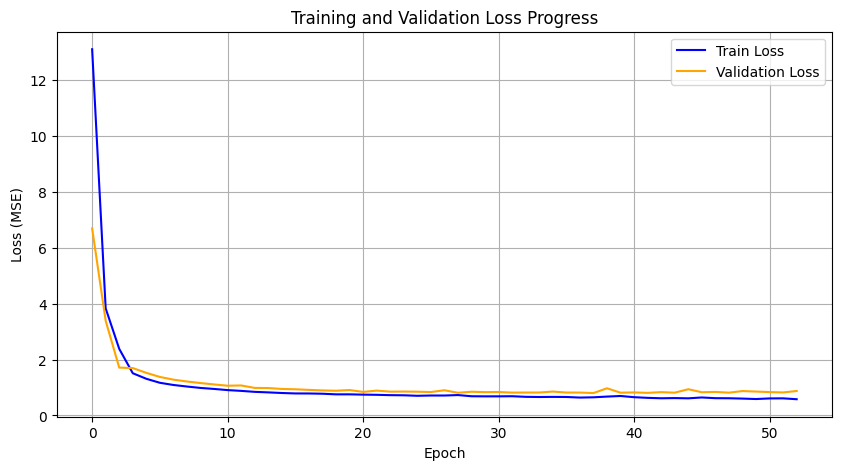

Test Set Performance Metrics:
Mean Squared Error (MSE): 0.9058
Root Mean Squared Error (RMSE): 0.9518
Mean Absolute Error (MAE): 0.6890
R-squared (R2 Score): 0.6256
Pearson Correlation: 0.8036


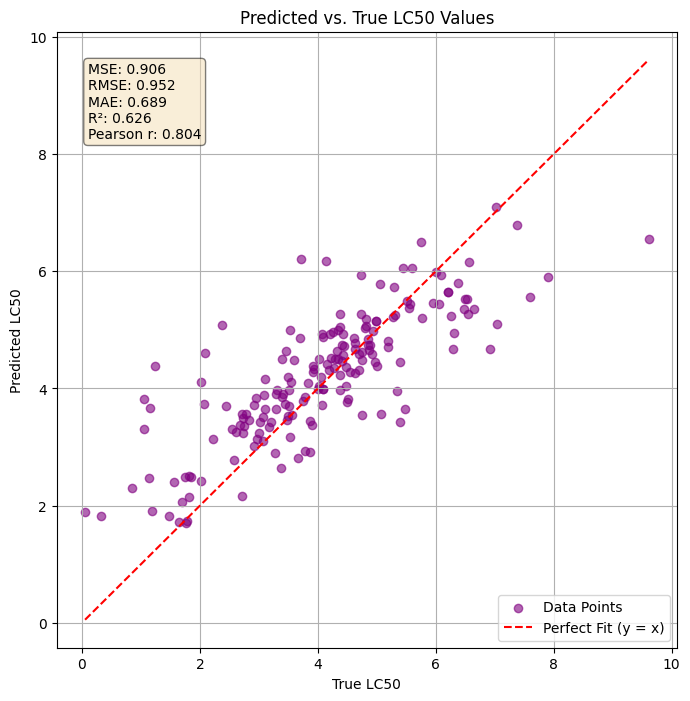

In [25]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Plot Loss Curves
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', color='blue')
plt.plot(val_losses, label='Validation Loss', color='orange')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training and Validation Loss Progress')
plt.legend()
plt.grid(True)
plt.show()

# 2. Collect Predictions on Test Set
model.eval()
test_predictions = []
actual_values = []

with torch.no_grad():
    for inputs, targets in test_loader:
        outputs = model(inputs)
        test_predictions.extend(outputs.numpy())
        actual_values.extend(targets.numpy())

test_predictions = np.array(test_predictions).flatten()
actual_values = np.array(actual_values).flatten()

# 3. Calculate Performance Metrics
mse = mean_squared_error(actual_values, test_predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(actual_values, test_predictions)
r2 = r2_score(actual_values, test_predictions)
pearson_corr, _ = pearsonr(actual_values, test_predictions)

print("Test Set Performance Metrics:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")
print(f"Pearson Correlation: {pearson_corr:.4f}")

# 4. Plot Scatter Plot of Predicted vs. True LC50
plt.figure(figsize=(8, 8))
plt.scatter(actual_values, test_predictions, alpha=0.6, color='purple', label='Data Points')

# Ideal line y = x
min_val = min(actual_values.min(), test_predictions.min())
max_val = max(actual_values.max(), test_predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Fit (y = x)')

plt.xlabel('True LC50')
plt.ylabel('Predicted LC50')
plt.title('Predicted vs. True LC50 Values')
plt.legend()
plt.grid(True)

# Annotate metrics on the plot
textstr = '\n'.join((
    f'MSE: {mse:.3f}',
    f'RMSE: {rmse:.3f}',
    f'MAE: {mae:.3f}',
    f'R²: {r2:.3f}',
    f'Pearson r: {pearson_corr:.3f}'
))
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
plt.gca().text(0.05, 0.95, textstr, transform=plt.gca().transAxes, fontsize=10,
        verticalalignment='top', bbox=props)

plt.show()

## Exercise 2: Encoding Constraints (California Housing Dataset)

In this exercise, we work with the California Housing dataset. House prices are strictly non-negative. We will enforce this physical constraint by introducing a `Softplus` activation function at the output layer of our neural network.

In [26]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
from torch.utils.data import TensorDataset, DataLoader

# 1. Load California Housing Dataset
housing = fetch_california_housing(as_frame=True)
X_house = housing.data
y_house = housing.target

# 2. Split dataset: 70% Train, 10% Val, 20% Test
X_train_val_h, X_test_h, y_train_val_h, y_test_h = train_test_split(
    X_house, y_house, test_size=0.20, random_state=42
)
X_train_h, X_val_h, y_train_h, y_val_h = train_test_split(
    X_train_val_h, y_train_val_h, test_size=0.125, random_state=42
)

# 3. Standardize Features
scaler_h = StandardScaler()
X_train_scaled_h = scaler_h.fit_transform(X_train_h)
X_val_scaled_h = scaler_h.transform(X_val_h)
X_test_scaled_h = scaler_h.transform(X_test_h)

# 4. Convert to PyTorch Tensors
X_train_t_h = torch.tensor(X_train_scaled_h, dtype=torch.float32)
y_train_t_h = torch.tensor(y_train_h.values, dtype=torch.float32).unsqueeze(1)

X_val_t_h = torch.tensor(X_val_scaled_h, dtype=torch.float32)
y_val_t_h = torch.tensor(y_val_h.values, dtype=torch.float32).unsqueeze(1)

X_test_t_h = torch.tensor(X_test_scaled_h, dtype=torch.float32)
y_test_t_h = torch.tensor(y_test_h.values, dtype=torch.float32).unsqueeze(1)

# 5. Create PyTorch DataLoaders
batch_size_h = 64
train_loader_h = DataLoader(TensorDataset(X_train_t_h, y_train_t_h), batch_size=batch_size_h, shuffle=True)
val_loader_h = DataLoader(TensorDataset(X_val_t_h, y_val_t_h), batch_size=batch_size_h, shuffle=False)
test_loader_h = DataLoader(TensorDataset(X_test_t_h, y_test_t_h), batch_size=batch_size_h, shuffle=False)

print("California Housing dataset successfully loaded and scaled!")
print(f"Train size: {X_train_scaled_h.shape}, Val size: {X_val_scaled_h.shape}, Test size: {X_test_scaled_h.shape}")

California Housing dataset successfully loaded and scaled!
Train size: (14448, 8), Val size: (2064, 8), Test size: (4128, 8)


### Neural Network with Output Constraint
We define a model that maps standard layers to an output layer followed by `nn.Softplus()`. Softplus function is defined as $f(x) = \ln(1 + e^x)$, which smoothly maps outputs strictly into $[0, \infty)$ range without numerical instability issues that can occur with `torch.exp`.

In [27]:
import torch.nn as nn

class ConstrainedHousingRegressor(nn.Module):
    def __init__(self, input_dim):
        super(ConstrainedHousingRegressor, self).__init__()
        # Linear layers mapping input features to hidden units
        self.fc1 = nn.Linear(input_dim, 64)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(32, 1)
        # Enforces output is strictly non-negative
        self.non_negative_activation = nn.Softplus()

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu1(out)
        out = self.fc2(out)
        out = self.relu2(out)
        out = self.fc3(out)
        # Output activation constraint
        out = self.non_negative_activation(out)
        return out

house_model = ConstrainedHousingRegressor(input_dim=X_train_scaled_h.shape[1])
print("Housing Network Structure:")
print(house_model)

Housing Network Structure:
ConstrainedHousingRegressor(
  (fc1): Linear(in_features=8, out_features=64, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (non_negative_activation): Softplus(beta=1.0, threshold=20.0)
)


### Training with Early Stopping
We will optimize the model using Adam optimizer and monitor MSE Loss with Early Stopping.

In [28]:
import torch.optim as optim

# Configure training objects
criterion_h = nn.MSELoss()
optimizer_h = optim.Adam(house_model.parameters(), lr=0.005)
early_stopping_h = EarlyStopping(patience=15)

train_losses_h = []
val_losses_h = []

epochs_h = 100
for epoch in range(epochs_h):
    house_model.train()
    running_train_loss = 0.0
    for inputs, targets in train_loader_h:
        optimizer_h.zero_grad()
        outputs = house_model(inputs)
        loss = criterion_h(outputs, targets)
        loss.backward()
        optimizer_h.step()
        running_train_loss += loss.item() * inputs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader_h.dataset)
    train_losses_h.append(epoch_train_loss)

    house_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader_h:
            outputs = house_model(inputs)
            loss = criterion_h(outputs, targets)
            running_val_loss += loss.item() * inputs.size(0)

    epoch_val_loss = running_val_loss / len(val_loader_h.dataset)
    val_losses_h.append(epoch_val_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:03d}/{epochs_h} - Train Loss: {epoch_train_loss:.4f} - Val Loss: {epoch_val_loss:.4f}")

    early_stopping_h(epoch_val_loss)
    if early_stopping_h.early_stop:
        print(f"-> Early stopping triggered at epoch {epoch+1}! Best Val Loss: {early_stopping_h.best_loss:.4f}")
        break

Epoch 001/100 - Train Loss: 0.7542 - Val Loss: 0.4225
Epoch 010/100 - Train Loss: 0.3252 - Val Loss: 0.3195
Epoch 020/100 - Train Loss: 0.2835 - Val Loss: 0.3076
Epoch 030/100 - Train Loss: 0.2680 - Val Loss: 0.2944
Epoch 040/100 - Train Loss: 0.2671 - Val Loss: 0.2942
Epoch 050/100 - Train Loss: 0.2552 - Val Loss: 0.2856
Epoch 060/100 - Train Loss: 0.2521 - Val Loss: 0.2763
Epoch 070/100 - Train Loss: 0.2452 - Val Loss: 0.2889
Epoch 080/100 - Train Loss: 0.2369 - Val Loss: 0.2766
Epoch 090/100 - Train Loss: 0.2357 - Val Loss: 0.2643
Epoch 100/100 - Train Loss: 0.2332 - Val Loss: 0.2853


### Test Evaluation
Now, we evaluate our output-constrained network on the unseen California Housing test dataset.

In [29]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

house_model.eval()
test_preds_h = []
actual_vals_h = []

with torch.no_grad():
    for inputs, targets in test_loader_h:
        outputs = house_model(inputs)
        test_preds_h.extend(outputs.numpy())
        actual_vals_h.extend(targets.numpy())

test_preds_h = np.array(test_preds_h).flatten()
actual_vals_h = np.array(actual_vals_h).flatten()

mse_h = mean_squared_error(actual_vals_h, test_preds_h)
mae_h = mean_absolute_error(actual_vals_h, test_preds_h)
r2_h = r2_score(actual_vals_h, test_preds_h)

print("California Housing Constrained Model Evaluation:")
print(f"Test Mean Squared Error (MSE): {mse_h:.4f}")
print(f"Test Mean Absolute Error (MAE): {mae_h:.4f}")
print(f"R-squared (R2 Score): {r2_h:.4f}")

California Housing Constrained Model Evaluation:
Test Mean Squared Error (MSE): 0.2726
Test Mean Absolute Error (MAE): 0.3436
R-squared (R2 Score): 0.7920
